# 115 · why `freq_cls` averages the bands, and the old gate + flatten didn't
Two src9 `transformer2` runs, 1000 ep, the same data and recipe, differing only in how each laser's 18 band tokens become **one** token:

| run | per laser: 18 band tokens → 1 token | over lasers: 100 tokens → 1 embedding | ID IoU@.08 | OOD |
|---|---|---|---|---|
| `s9-t2-ref-vase-1k` | gate, then **flatten + Linear(18·128 → 128)** | flatten + Linear(100·128 → 1024) | .695 | .386 |
| `s9-t2-cls-vase-1k` | **`freq_cls`** token, read out after 2 attention blocks | `laser_cls` token | .537 | .304 |

The claim this notebook builds up, step by step:
1. flatten + Linear is the same thing as giving **every band its own matrix** `W_b` (`out = Σ_b W_b x_b`). Band 3's feature k and band 10's
   feature k land in different output directions, so the output knows *which band* said what.
2. attention pooling is `out = Σ_b α_b V x_b` with **one matrix `V` for every band**. It can only choose *how much* of each band to take.
   When every band matters a bit (they do here), the best it can do is a near-uniform average, which stacks the bands on top of each other.
3. so the fix is to put band-specific weights back *before* the pooling: a per-band embedding `W_x^b`.

Everything runs on CPU in fp32 (a training queue owns the GPU), on 400 eval samples.

In [1]:
import os, sys, math
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9, score
from arch.transformer2 import Transformer2
torch.set_num_threads(8); torch.manual_seed(0); np.random.seed(0)
REF, CLS = "s9-t2-ref-vase-1k", "s9-t2-cls-vase-1k"
N, BS = 400, 20
plt.rcParams.update({"figure.dpi": 90, "font.size": 10})

## 1 · what goes in: one laser's spectrum becomes 18 band tokens
Each sample has 100 lasers (a 10×10 grid), each with a spectrum of 1170 bins (100–1000 Hz, ~0.77 Hz apart) × 2 channels (x and y shift).
The spectrum is cut into **18 bands of 65 bins** (~50 Hz each). One band = 65 bins × 2 channels = **130 numbers** = one token.
A single `Linear(130 → 128)` (the **same** one for every band) turns it into a 128-d vector, and three fixed vectors are added:
the band's position (`freq_band_emb`), the laser's identity + position, and the box.
Then 2 attention blocks run over the 18 tokens of each laser, separately for every laser (100 × B sequences).
The question of this notebook is the last step: **18 tokens × 128 → 1 token × 128 per laser**.

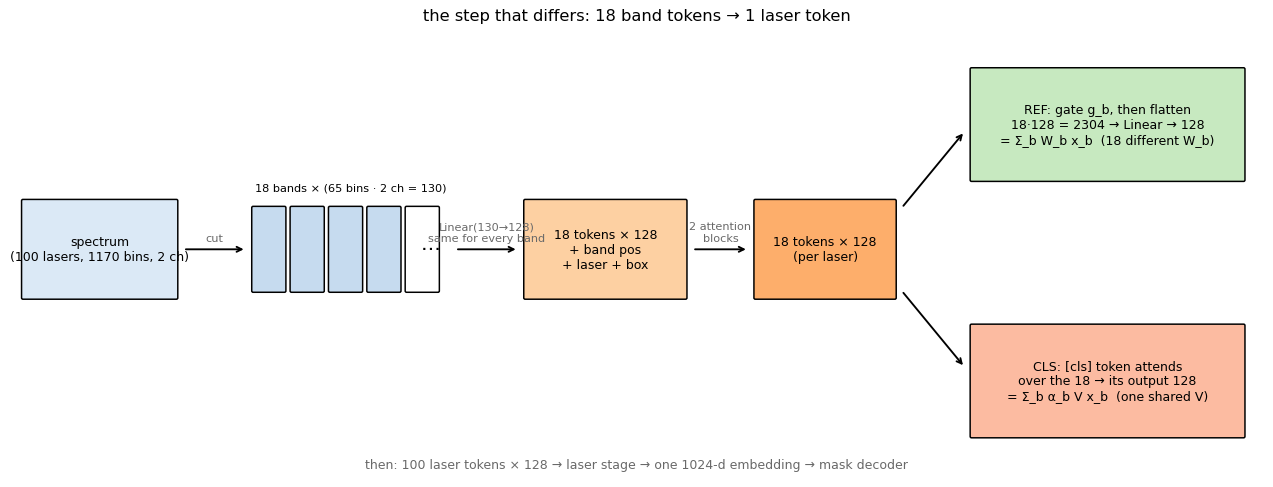

In [2]:
def box(ax, x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=color, ec="k", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10)
def arrow(ax, x0, y0, x1, y1, text=""):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", lw=1.5))
    if text: ax.text((x0 + x1) / 2, (y0 + y1) / 2 + .12, text, ha="center", fontsize=9, color="dimgray")
fig, ax = plt.subplots(figsize=(18, 6.5)); ax.set_xlim(0, 18); ax.set_ylim(0, 6.5); ax.axis("off")
box(ax, .2, 2.6, 2.2, 1.4, "spectrum\n(100 lasers, 1170 bins, 2 ch)", "#dbe9f6")
arrow(ax, 2.5, 3.3, 3.4, 3.3, "cut")
for i in range(5): box(ax, 3.5 + i * .55, 2.7, .45, 1.2, "", "#c6dbef" if i < 4 else "white")
ax.text(4.9, 4.15, "18 bands × (65 bins · 2 ch = 130)", ha="center", fontsize=9); ax.text(5.9, 3.3, "…", fontsize=16)
arrow(ax, 6.4, 3.3, 7.3, 3.3, "Linear(130→128)\nsame for every band")
box(ax, 7.4, 2.6, 2.3, 1.4, "18 tokens × 128\n+ band pos\n+ laser + box", "#fdd0a2")
arrow(ax, 9.8, 3.3, 10.6, 3.3, "2 attention\nblocks")
box(ax, 10.7, 2.6, 2.0, 1.4, "18 tokens × 128\n(per laser)", "#fdae6b")
arrow(ax, 12.8, 3.9, 13.7, 5.0); arrow(ax, 12.8, 2.7, 13.7, 1.6)
box(ax, 13.8, 4.3, 3.9, 1.6, "REF: gate g_b, then flatten\n18·128 = 2304 → Linear → 128\n= Σ_b W_b x_b  (18 different W_b)", "#c7e9c0")
box(ax, 13.8, .6, 3.9, 1.6, "CLS: [cls] token attends\nover the 18 → its output 128\n= Σ_b α_b V x_b  (one shared V)", "#fcbba1")
ax.text(9, .15, "then: 100 laser tokens × 128 → laser stage → one 1024-d embedding → mask decoder", ha="center", fontsize=10, color="dimgray")
ax.set_title("the step that differs: 18 band tokens → 1 laser token", fontsize=13); plt.show()

## 2 · toy example: 3 bands, 2 numbers per band
Two different "spectra": **A** has energy in band 1, **B** has the same energy in band 3. A good readout must give A ≠ B.
- **shared V + average** (what an attention pool with uniform weights is): both give `V · mean(x_b)`. The mean of the bands is the same
  for A and B, so the outputs are **identical**. Band identity is gone.
- adding a fixed band position `p_b` to each token does **not** help: the mean of `x_b + p_b` is `mean(x_b) + mean(p_b)`, and `mean(p_b)` is the
  same constant for every sample.
- **per-band W_b** (flatten + Linear): `W_1 x_1` vs `W_3 x_3` use different matrices, so A ≠ B.

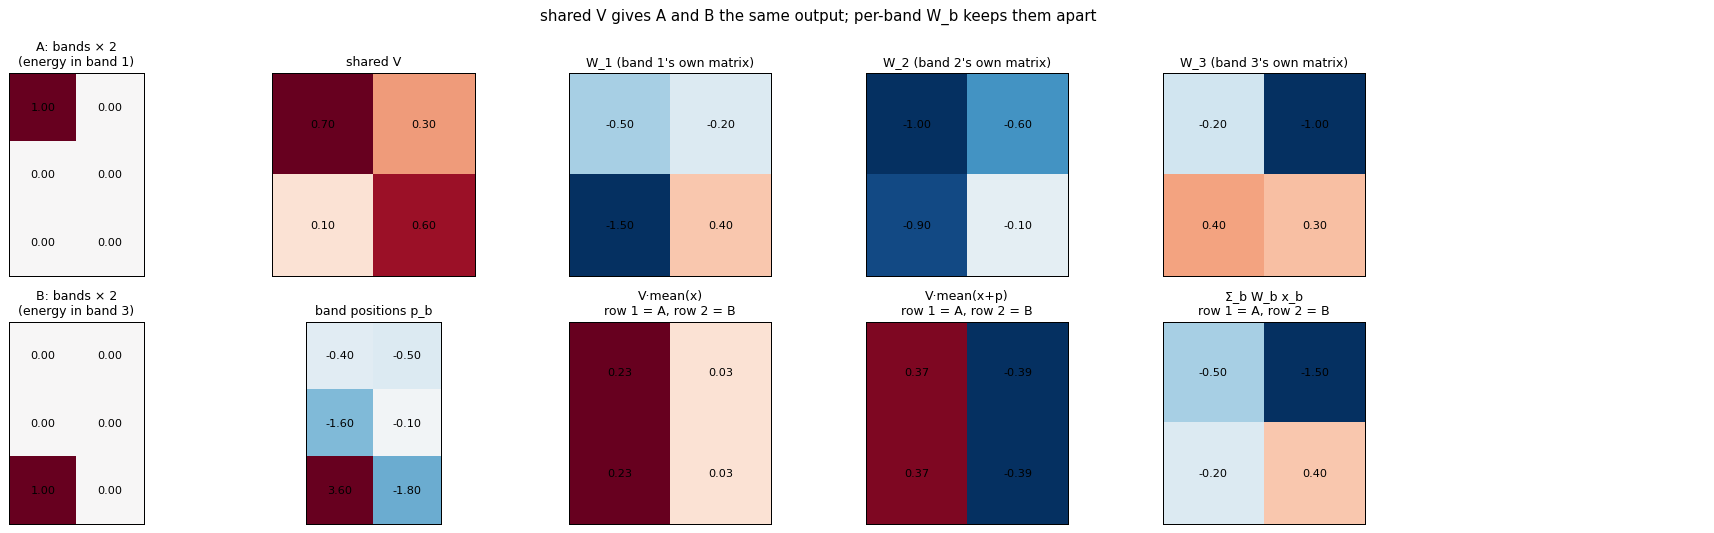

shared V + mean:   A [0.23333333432674408, 0.03333333507180214]  B [0.23333333432674408, 0.03333333507180214]
+ band positions:  A [0.36666661500930786, -0.3933333456516266]  B [0.36666661500930786, -0.3933333456516266]
per-band W_b:      A [-0.5, -1.5]  B [-0.20000000298023224, 0.4000000059604645]


In [3]:
xA = torch.tensor([[1., 0.], [0., 0.], [0., 0.]])   # (bands=3, 2): energy in band 1
xB = torch.tensor([[0., 0.], [0., 0.], [1., 0.]])   # energy in band 3
g = torch.Generator().manual_seed(1)
V = torch.randn(2, 2, generator=g).round(decimals=1)                 # one shared value matrix
W = torch.randn(3, 2, 2, generator=g).round(decimals=1)              # one matrix per band
p = torch.randn(3, 2, generator=g).round(decimals=1)                 # fixed band positions
shared = lambda x: V @ x.mean(0)                                     # uniform attention pool: V · mean_b x_b
shared_pos = lambda x: V @ (x + p).mean(0)
perband = lambda x: torch.einsum("bij,bj->i", W, x)                  # Σ_b W_b x_b
def hm(ax, m, title, cmap="RdBu_r"):
    m = np.atleast_2d(np.asarray(m)); v = max(abs(m).max(), 1e-6)
    ax.imshow(m, cmap=cmap, vmin=-v, vmax=v); ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    for (i, j), z in np.ndenumerate(m): ax.text(j, i, f"{z:.2f}", ha="center", va="center", fontsize=9)
fig, axs = plt.subplots(2, 6, figsize=(20, 6))
hm(axs[0, 0], xA, "A: bands × 2\n(energy in band 1)"); hm(axs[1, 0], xB, "B: bands × 2\n(energy in band 3)")
hm(axs[0, 1], V, "shared V"); hm(axs[1, 1], p, "band positions p_b")
for b in range(3): hm(axs[0, 2 + b], W[b], f"W_{b + 1} (band {b + 1}'s own matrix)")
for j, (name, f) in enumerate([("V·mean(x)", shared), ("V·mean(x+p)", shared_pos), ("Σ_b W_b x_b", perband)]):
    hm(axs[1, 2 + j], torch.stack([f(xA), f(xB)]), f"{name}\nrow 1 = A, row 2 = B")
axs[0, 5].axis("off"); axs[1, 5].axis("off")
plt.suptitle("shared V gives A and B the same output; per-band W_b keeps them apart", fontsize=12); plt.tight_layout(); plt.show()
print("shared V + mean:   A", shared(xA).tolist(), " B", shared(xB).tolist())
print("+ band positions:  A", shared_pos(xA).tolist(), " B", shared_pos(xB).tolist())
print("per-band W_b:      A", perband(xA).tolist(), " B", perband(xB).tolist())

### but attention is not uniform: can it rescue band identity?
Partly. If the weights depend on the content, the pool can **peak** on the loud band. The value then carries that band's position,
`V(x_3 + p_3)`, so A ≠ B again: attention works as "pick one band".

It breaks when the answer is a **pattern across several bands**. A weighted average of positions only keeps their *average*. Our band positions
come from a small MLP of log f, so they are smooth in frequency, roughly a line. Below, 4 bands with positions on a line: A' is loud in bands
{1, 4}, B' in bands {2, 3}. Attention splits its weight over the loud bands, and the average position of {1, 4} equals that of {2, 3}, so the outputs
are **identical**. Σ W_b x_b separates them. With 18 bands and a spectrum where many bands matter at once, this happens all the time: one
weighted average per head can't keep 18 bands apart.

attention pool A: weights [0.96, 0.02, 0.02] -> output [0.275, -0.248]
attention pool B: weights [0.02, 0.02, 0.96] -> output [2.557, -0.608]
attention pool A': weights [0.49, 0.01, 0.01, 0.49] -> output [0.693, 0.109]   per-band W_b: [1.9, -0.7]
attention pool B': weights [0.01, 0.49, 0.49, 0.01] -> output [0.693, 0.109]   per-band W_b: [-1.9, 0.7]


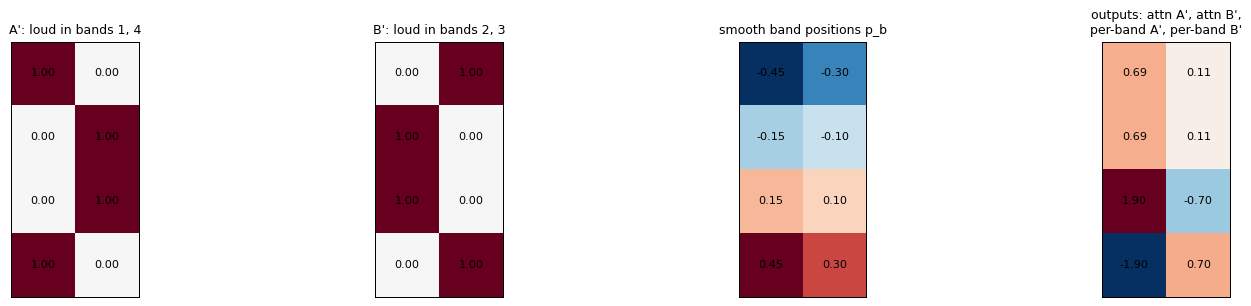

In [4]:
q = torch.tensor([4., 0.])                                            # the query looks for feature 0 ("loud")
def attn_pool(x, p, V):
    a = (x @ q).softmax(0); return a, V @ (a[:, None] * (x + p)).sum(0)   # weights from the content, values carry the position
for name, x in [("A", xA), ("B", xB)]:
    a, o = attn_pool(x, p, V); print(f"attention pool {name}: weights {[round(v, 2) for v in a.tolist()]} -> output {[round(v, 3) for v in o.tolist()]}")
quiet, loud = [0., 1.], [1., 0.]
xA4 = torch.tensor([loud, quiet, quiet, loud])                         # loud in bands 1 and 4
xB4 = torch.tensor([quiet, loud, loud, quiet])                         # loud in bands 2 and 3
p4 = (torch.arange(4.) - 1.5)[:, None] * torch.tensor([.3, .2])        # smooth positions: a line in frequency
W4 = torch.randn(4, 2, 2, generator=g).round(decimals=1)
perband4 = lambda x: torch.einsum("bij,bj->i", W4, x)
for name, x in [("A'", xA4), ("B'", xB4)]:
    a, o = attn_pool(x, p4, V)
    print(f"attention pool {name}: weights {[round(v, 2) for v in a.tolist()]} -> output {[round(v, 3) for v in o.tolist()]}   per-band W_b: {[round(v, 3) for v in perband4(x).tolist()]}")
fig, axs = plt.subplots(1, 4, figsize=(18, 3.5))
hm(axs[0], xA4, "A': loud in bands 1, 4"); hm(axs[1], xB4, "B': loud in bands 2, 3"); hm(axs[2], p4, "smooth band positions p_b")
hm(axs[3], torch.stack([attn_pool(xA4, p4, V)[1], attn_pool(xB4, p4, V)[1], perband4(xA4), perband4(xB4)]), "outputs: attn A', attn B',\nper-band A', per-band B'")
plt.tight_layout(); plt.show()

### flatten + Linear **is** Σ_b W_b x_b
`Linear(18·128 → 128)` on the flattened `(18, 128)` has a weight `(128, 2304)`. Its columns `b·128 … b·128+127` only ever touch band b,
so cutting the weight into 18 blocks of `(128, 128)` gives the per-band matrices: `W.view(128, 18, 128)[:, b]`. Checked below on the real
`pool_o` of the ref checkpoint.

In [5]:
sd_ref = torch.load(ROOT / f"runs/{REF}/checkpoints/latest-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"]
sd_cls = torch.load(ROOT / f"runs/{CLS}/checkpoints/latest-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"]
Wo = sd_ref["encoder.freq_enc.pool_o.weight"]                       # (128, 18*128)
Wb = Wo.view(128, 18, 128).permute(1, 0, 2)                          # (18, 128 out, 128 in): band b's own matrix
x = torch.randn(5, 18, 128)
print("pool_o weight", tuple(Wo.shape), "-> 18 blocks", tuple(Wb.shape))
print("max |flatten @ W.T - Σ_b W_b x_b| =", (x.flatten(1) @ Wo.T - torch.einsum("boi,nbi->no", Wb, x)).abs().max().item())

pool_o weight (128, 2304) -> 18 blocks (18, 128, 128)
max |flatten @ W.T - Σ_b W_b x_b| = 0.0


## 3 · load both checkpoints and 400 eval samples
The cls checkpoint was trained with the old single `cls` flag, which had a LayerNorm (`cls_norm`) on the `freq_cls` output. Current
`transformer2.py` dropped it, so the forward is written out inline below (`encode`), once for both models, and it also keeps every
intermediate: band tokens, gate / attention weights, laser tokens. IoU on the 400 samples checks the load (previous diagnosis: ref ≈ .74, cls ≈ .58).

In [6]:
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
items = []
for f in sorted((ROOT / f"runs/{REF}/outputs_history/eval").glob("*/*/ep1000-ba*.pt")):
    bx, split = f.parent.parent.name, f.parent.name
    if CAT.get((bx, split)) not in ("id", "unseen-position"): continue
    info = torch.load(f, weights_only=False, map_location="cpu")["info"]
    for i in range(len(info["experiment"])): items.append((info["experiment"][i], info["sample_id"][i], int(info["position_id"][i]), int(info["speaker"][i])))
sel = [items[i] for i in np.random.choice(len(items), N, replace=False)]
X, BOXN, Y = [], [], []
for exp, sid, pos, spk in sel:
    d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
    s = D9.load_fft(d, meta, "tukey").abs(); X.append((s / s.std()).float()); BOXN.append(meta["box"]); Y.append(score.truth(exp, sid, pos, spk, 64, 64))
X, Y = torch.stack(X), np.stack(Y)
NAMES = sorted(set(BOXN)); assert len(NAMES) == 3, NAMES
BOX = torch.tensor([NAMES.index(b) for b in BOXN])
print("X", tuple(X.shape), "boxes", NAMES, {b: BOXN.count(b) for b in NAMES})

def load(sd, cls):
    nobj, K = sd["object_head.2.weight"].shape[0], sd["n_objects_head.2.weight"].shape[0] - 1
    info = dict(freq_range=(100.0, 1000.0), n_freqs=1170, n_laser_rows=10, n_laser_cols=10, n_channels=2, boxes=NAMES,
                cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].pow(-2), objects=[str(i) for i in range(nobj + 1)], n_objects=list(range(K + 1)))
    m = Transformer2(info, freq_cls=cls, laser_cls=cls)
    missing, unexpected = m.load_state_dict(sd, strict=False)
    assert not missing and set(unexpected) <= {"encoder.freq_enc.cls_norm.weight", "encoder.freq_enc.cls_norm.bias"}, (missing, unexpected)
    norm = None
    if cls: norm = nn.LayerNorm(128); norm.weight.data, norm.bias.data = sd["encoder.freq_enc.cls_norm.weight"], sd["encoder.freq_enc.cls_norm.bias"]
    return m.eval(), norm
m_ref, _ = load(sd_ref, 0)
m_cls, cls_norm = load(sd_cls, 1)

def attn(blk, x):
    """the attention weights block `blk` uses on input x: (N,H,T,T)"""
    q, k, _ = blk.qkv(blk.n1(x)).view(*x.shape[:2], 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    return (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)

@torch.no_grad()
def encode(m, x, bx, norm=None):
    """the transformer2 encoder written out, keeping the intermediates. norm = the old cls checkpoint's cls_norm"""
    e, fe, le = m.encoder, m.encoder.freq_enc, m.encoder.laser_enc
    B, L = x.shape[:2]
    xn = e.normalize(x, bx)                                                            # (B,L,1170,2) z-scored
    laser = e.laser_emb + e.laser_pos(e.laser_fourier)                                 # (L,128)
    t = fe.embed(xn.reshape(B, L, 18, -1)) + fe.freq_band_emb(e.freq_band_logf[:, None])[None, None] + laser[None, :, None] + fe.box_emb(bx)[:, None, None]
    t = t.flatten(0, 1)                                                                # (B*L,18,128)
    out = {} if fe.cls else dict(xn=xn)                                                # the input is the same for both models: keep it once
    if fe.cls: t = torch.cat([fe.freq_cls.expand(len(t), 1, -1), t], 1)               # (B*L,19,128)
    A = []
    for i, blk in enumerate(fe.freqs):
        if i == len(fe.freqs) - 1: last_in = t                                         # input of the last freq block
        A.append(attn(blk, t)); t = blk(t)
    if fe.cls:
        out["freq_attn"] = torch.stack(A, 1)[:, :, :, 0].view(B, L, len(A), fe.heads, -1)  # (B,L,layers,H,19): what the cls token reads
        blk = fe.freqs[-1]; v = F.linear(blk.n1(last_in), blk.qkv.weight[256:], blk.qkv.bias[256:])  # V x_b in the last block
        a = A[-1][:, :, 0, 1:]                                                         # (B*L,H,18) cls -> band weights, last block
        out["summand"] = (v[:, 1:].view(B * L, 18, fe.heads, -1) * a.transpose(1, 2)[..., None]).flatten(2).view(B, L, 18, -1)  # α_b V x_b (per head, concatenated)
        tok = norm(t[:, 0]).view(B, L, -1)                                             # the cls output (old checkpoint: LayerNorm'd)
    else:
        t = t.view(B, L, 18, -1)
        k = fe.pool_k(fe.pool_norm(t)).view(B, L, 18, fe.heads, -1)
        a = torch.einsum("blphe,he->blhp", k, fe.pool_q).div(math.sqrt(k.shape[-1])).softmax(-1)  # (B,L,H,18)
        out["gate"] = a.mean(2) * 18                                                   # (B,L,18): 1 = uniform
        tok = fe.pool_o((t * out["gate"][..., None]).reshape(B, L, -1))
        out["summand"] = torch.einsum("boi,xlbi->xlbo", Wb, t * out["gate"][..., None])  # g_b W_b x_b
    out["laser_tok_raw"] = tok                                                         # before + laser
    z = tok + laser
    out["laser_tok"] = z
    if le.cls: z = torch.cat([le.laser_cls.expand(B, 1, -1), z], 1)
    A = []
    for blk in le.lasers: A.append(attn(blk, z)); z = blk(z)
    out["laser_attn"] = torch.stack(A, 1)                                              # (B,layers,H,T,T)
    emb = le.to_emb(z[:, 0]) if le.cls else le.to_emb(z)
    out["mask"] = m.decoder(emb)[:, 0].sigmoid()
    return out

def run(m, norm=None):
    outs = [encode(m, X[i:i + BS], BOX[i:i + BS], norm) for i in range(0, N, BS)]
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}
R, C = run(m_ref), run(m_cls, cls_norm)
iou = lambda P: np.mean([((P[i] > .08) & (Y[i] > .5)).sum() / max(((P[i] > .08) | (Y[i] > .5)).sum(), 1) for i in range(N)])
print(f"IoU@.08 on these {N} samples: ref {iou(R['mask'].numpy()):.3f}   cls {iou(C['mask'].numpy()):.3f}")

X (400, 100, 1170, 2) boxes ['cardboard', 'gastronorm', 'green-plastic'] {'cardboard': 152, 'gastronorm': 107, 'green-plastic': 141}
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


IoU@.08 on these 400 samples: ref 0.739   cls 0.580


## 4 · the ref model: the 18 matrices W_b are different from each other, and the gate does almost nothing
Left: how big each band's matrix is. Middle: cosine similarity between the 18 matrices (flattened). If they were all the same matrix
(= shared V), this would be all 1s; near 0 means each band gets its **own** projection. Right: two of them.

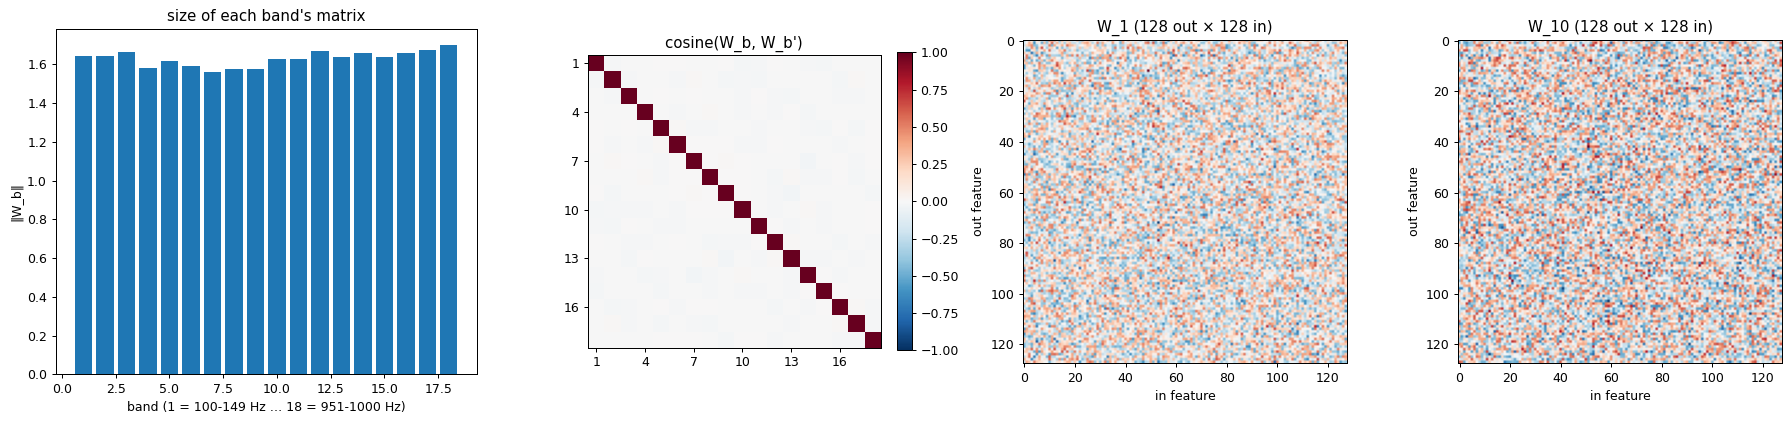

off-diagonal cosine between band matrices: mean -0.005, max 0.014   (shared V would be 1.0)


In [7]:
nrm = Wb.flatten(1).norm(dim=1)
cos = F.normalize(Wb.flatten(1), dim=1); cos = cos @ cos.T
fig, axs = plt.subplots(1, 4, figsize=(20, 4.8), gridspec_kw=dict(width_ratios=[1.3, 1, 1, 1]))
axs[0].bar(range(1, 19), nrm); axs[0].set(xlabel="band (1 = 100-149 Hz … 18 = 951-1000 Hz)", ylabel="‖W_b‖", title="size of each band's matrix")
im = axs[1].imshow(cos, cmap="RdBu_r", vmin=-1, vmax=1); axs[1].set_title("cosine(W_b, W_b')"); plt.colorbar(im, ax=axs[1], fraction=.046)
axs[1].set_xticks(range(0, 18, 3), range(1, 19, 3)); axs[1].set_yticks(range(0, 18, 3), range(1, 19, 3))
for ax, b in zip(axs[2:], [0, 9]):
    v = Wb[b].abs().max(); ax.imshow(Wb[b], cmap="RdBu_r", vmin=-v, vmax=v); ax.set(title=f"W_{b + 1} (128 out × 128 in)", xlabel="in feature", ylabel="out feature")
plt.tight_layout(); plt.show()
off = cos[~torch.eye(18, dtype=bool)]
print(f"off-diagonal cosine between band matrices: mean {off.mean():.3f}, max {off.max():.3f}   (shared V would be 1.0)")

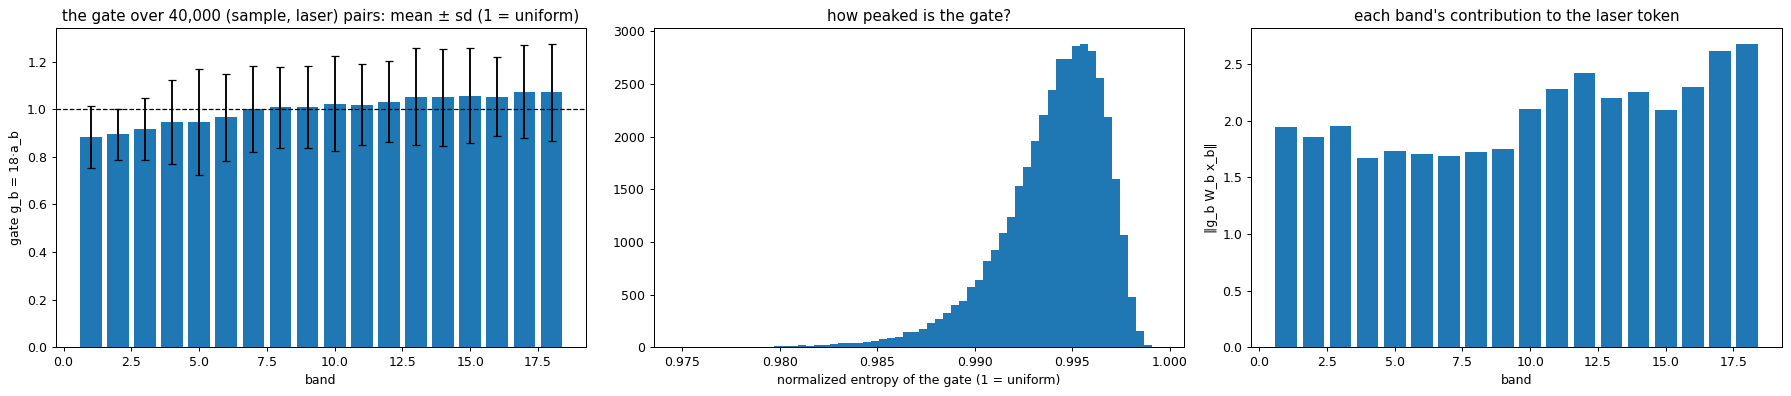

gate: mean entropy 0.994 (1 = uniform), mean max gate 1.40 (uniform = 1), range of band means 0.88-1.07


In [8]:
gate = R["gate"].flatten(0, 1)                                                         # (B*L,18), 1 = uniform
p = gate / 18; ent = -(p * p.clamp_min(1e-12).log()).sum(-1) / math.log(18)
contrib = R["summand"].flatten(0, 1).norm(dim=-1)                                     # ‖g_b W_b x_b‖ per (sample·laser, band)
fig, axs = plt.subplots(1, 3, figsize=(20, 4.5))
axs[0].bar(range(1, 19), gate.mean(0), yerr=gate.std(0), capsize=3); axs[0].axhline(1, color="k", ls="--", lw=1)
axs[0].set(xlabel="band", ylabel="gate g_b = 18·a_b", title="the gate over 40,000 (sample, laser) pairs: mean ± sd (1 = uniform)")
axs[1].hist(ent.numpy(), 60); axs[1].set(xlabel="normalized entropy of the gate (1 = uniform)", title="how peaked is the gate?")
axs[2].bar(range(1, 19), contrib.mean(0)); axs[2].set(xlabel="band", ylabel="‖g_b W_b x_b‖", title="each band's contribution to the laser token")
plt.tight_layout(); plt.show()
print(f"gate: mean entropy {ent.mean():.3f} (1 = uniform), mean max gate {gate.max(-1).values.mean():.2f} (uniform = 1), "
      f"range of band means {gate.mean(0).min():.2f}-{gate.mean(0).max():.2f}")

## 5 · the cls model: `freq_cls` attention is close to uniform
Each row = one (layer, head); each column = one of the 19 tokens it can read (the cls token itself + 18 bands). One sample, four lasers,
and the mean over all samples and lasers. Uniform over 19 tokens = 0.053.

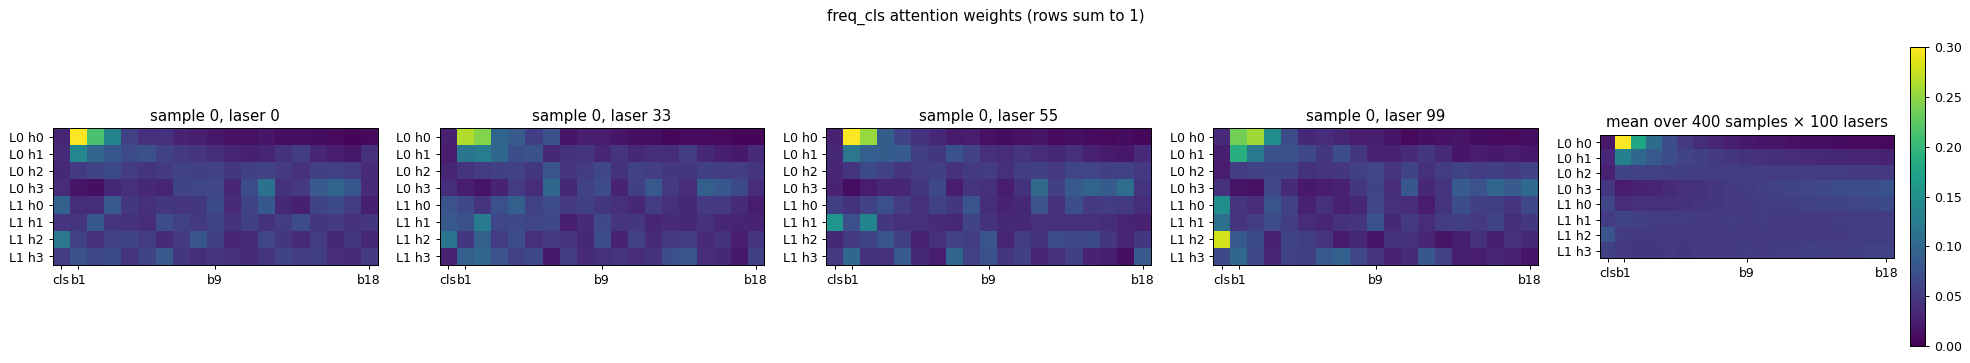

layer 0: entropy over the 18 bands per head [0.736, 0.953, 0.996, 0.962], max band weight 0.173 (uniform 0.056)
layer 1: entropy over the 18 bands per head [0.97, 0.975, 0.978, 0.95], max band weight 0.110 (uniform 0.056)


In [9]:
cls_row = C["freq_attn"]                                                               # what the cls token reads: (B,L,layers,H,19)
nl, nh = cls_row.shape[2:4]
fig, axs = plt.subplots(1, 5, figsize=(22, 4))
for ax, l in zip(axs[:4], [0, 33, 55, 99]):
    ax.imshow(cls_row[0, l].reshape(nl * nh, 19), cmap="viridis", vmin=0, vmax=.3); ax.set_title(f"sample 0, laser {l}")
    ax.set_yticks(range(nl * nh), [f"L{a} h{b}" for a in range(nl) for b in range(nh)]); ax.set_xticks([0, 1, 9, 18], ["cls", "b1", "b9", "b18"])
im = axs[4].imshow(cls_row.mean((0, 1)).reshape(nl * nh, 19), cmap="viridis", vmin=0, vmax=.3); axs[4].set_title("mean over 400 samples × 100 lasers")
axs[4].set_yticks(range(nl * nh), [f"L{a} h{b}" for a in range(nl) for b in range(nh)]); axs[4].set_xticks([0, 1, 9, 18], ["cls", "b1", "b9", "b18"])
plt.colorbar(im, ax=axs[4], fraction=.046); plt.suptitle("freq_cls attention weights (rows sum to 1)"); plt.tight_layout(); plt.show()
bands = cls_row[..., 1:] / cls_row[..., 1:].sum(-1, keepdim=True)
ent_c = -(bands * bands.clamp_min(1e-12).log()).sum(-1) / math.log(18)                # (B,L,layers,H)
for l in range(nl): print(f"layer {l}: entropy over the 18 bands per head {[round(v, 3) for v in ent_c[:, :, l].mean((0, 1)).tolist()]}, "
                          f"max band weight {bands[:, :, l].max(-1).values.mean():.3f} (uniform 0.056)")

### one shared V: what actually gets added up
In the last block the cls output is `Σ_b α_b · V x_b` (then the output projection + MLP), with one `V` (128 × 128) for **every** band.
The ref token is `Σ_b g_b W_b x_b`. Both are a sum of 18 vectors, one per band. If those 18 summands point in **similar** directions, the
sum is basically "a louder or quieter version of the same vector" and you can't tell afterwards which band contributed what. If they point in
**different** directions (near-orthogonal), the sum keeps each band readable. Middle / right: the cosine between the 18 summands of the same
laser (sample-dependent part only: each band's mean over samples removed).

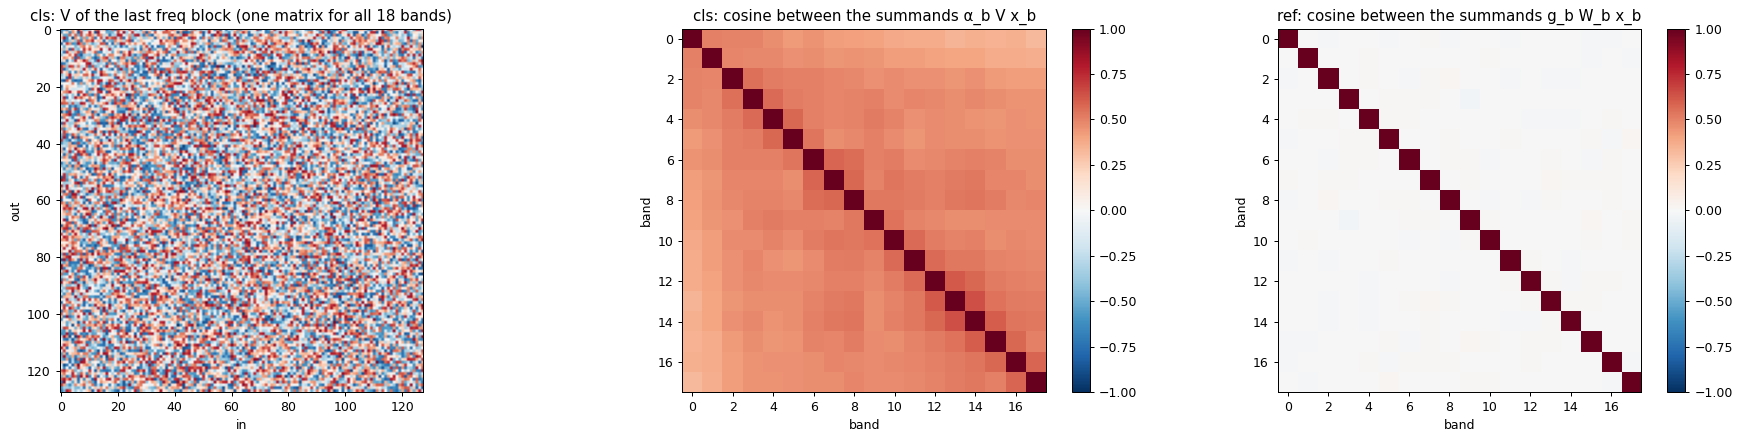

mean off-diagonal cosine between the 18 summands of a laser token: cls 0.481, ref 0.001


In [10]:
blk = m_cls.encoder.freq_enc.freqs[-1]
Vw = blk.qkv.weight[256:].detach()                                                     # (128,128): rows 256-383 of qkv = the value projection
def summand_cos(T):
    """(B,L,18,d) the 18 things that get summed into a laser token -> (18,18) mean cosine between them, same laser, sample-dependent part only"""
    T = F.normalize(T - T.mean(0, keepdim=True), dim=-1); return torch.einsum("nlbd,nlcd->bc", T, T) / (T.shape[0] * T.shape[1])
cc, cr = summand_cos(C["summand"]), summand_cos(R["summand"])
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
v = Vw.abs().max(); axs[0].imshow(Vw, cmap="RdBu_r", vmin=-v, vmax=v); axs[0].set(title="cls: V of the last freq block (one matrix for all 18 bands)", xlabel="in", ylabel="out")
for ax, M, t in [(axs[1], cc, "cls: cosine between the summands α_b V x_b"), (axs[2], cr, "ref: cosine between the summands g_b W_b x_b")]:
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1); ax.set(title=t, xlabel="band", ylabel="band"); plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()
off = ~torch.eye(18, dtype=bool)
print(f"mean off-diagonal cosine between the 18 summands of a laser token: cls {cc[off].mean():.3f}, ref {cr[off].mean():.3f}")

## 6 · the evidence: band identity is in the ref laser token, not in the cls one
Take the 128-d token each laser hands to the laser stage (before `+ laser`), remove each laser's mean over samples, and fit a linear
probe (ridge, 80/20 split by sample) for:
- **per-band energy**: the mean of the z-scored input over each band's 130 numbers, 18 targets. Can the token say *which band* was loud?
- the **folding test**: explain the token from the input, either from the full layout (18 × 130 = 2340 numbers) or from the **band-averaged
  patch** (the 130 numbers averaged over the 18 bands). If the token is ≈ "an average over bands", the folded patch explains almost as much
  as the full layout.

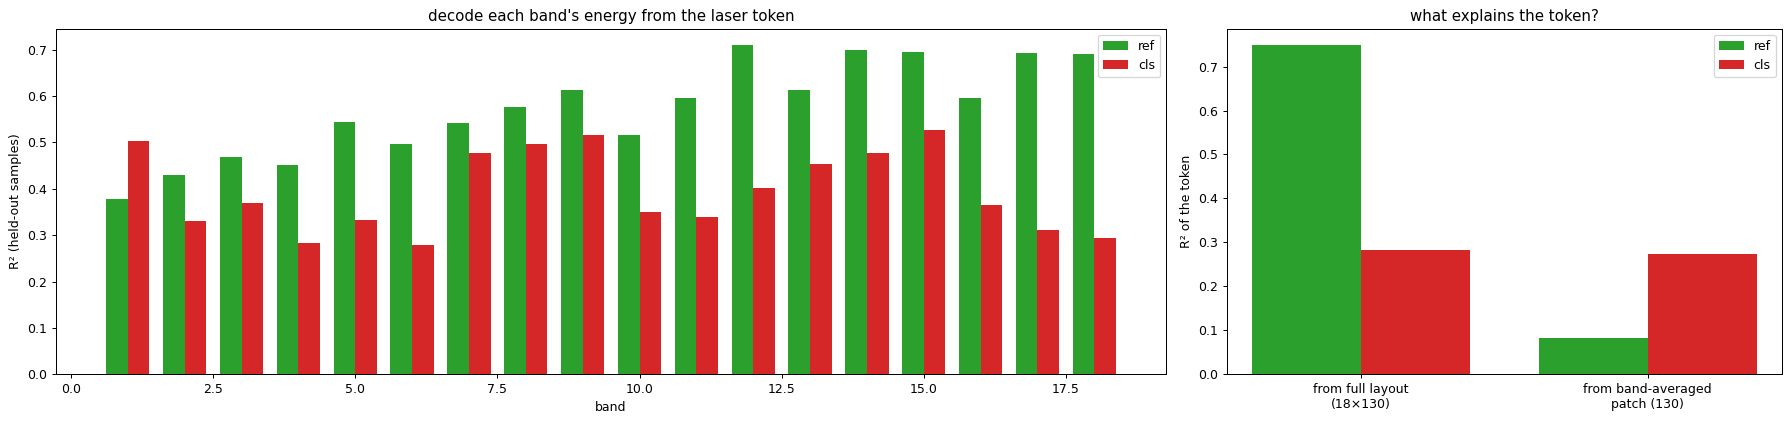

ref: band-energy R² mean 0.573; token R² from full 0.749 vs folded 0.082 (folded/full = 0.11)
cls: band-energy R² mean 0.395; token R² from full 0.282 vs folded 0.274 (folded/full = 0.97)


In [11]:
def center(T): return (T - T.mean(0, keepdim=True)).flatten(0, 1).float()           # (B,L,·) -> (B*L,·), per-laser mean removed
def ridge_r2(Xf, Yf, lam=1e-2):
    n = len(Xf) // 100 * 80                                                            # rows are (sample, laser): split by sample
    tr, te = slice(0, n), slice(n, None)
    mu, sd = Xf[tr].mean(0), Xf[tr].std(0) + 1e-8; Xs = (Xf - mu) / sd
    G = (Xs[tr].T @ Xs[tr]).double() + lam * n * torch.eye(Xs.shape[1], dtype=torch.float64)
    w = torch.linalg.solve(G, (Xs[tr].T @ (Yf[tr] - Yf[tr].mean(0))).double()).float()
    res = Yf[te] - Yf[tr].mean(0) - Xs[te] @ w
    return 1 - res.pow(2).sum(0) / (Yf[te] - Yf[te].mean(0)).pow(2).sum(0)            # R² per target
patch = R["xn"].reshape(N, 100, 18, 130)                                               # the same input for both models
energy = center(patch.mean(-1))                                                        # (B*L,18)
full, folded = center(patch.flatten(2)), center(patch.mean(2))                         # (B*L,2340), (B*L,130)
r2 = {}
for name, O in [("ref", R), ("cls", C)]:
    tok = center(O["laser_tok_raw"])
    r2[name] = dict(energy=ridge_r2(tok, energy), full=ridge_r2(full, tok).mean().item(), folded=ridge_r2(folded, tok).mean().item())
fig, axs = plt.subplots(1, 2, figsize=(20, 4.8), gridspec_kw=dict(width_ratios=[2, 1]))
w = .38
for i, (name, c) in enumerate([("ref", "tab:green"), ("cls", "tab:red")]):
    axs[0].bar(np.arange(1, 19) + (i - .5) * w, r2[name]["energy"].numpy(), w, label=name, color=c)
axs[0].set(xlabel="band", ylabel="R² (held-out samples)", title="decode each band's energy from the laser token"); axs[0].legend()
xs = np.arange(2)
for i, (name, c) in enumerate([("ref", "tab:green"), ("cls", "tab:red")]):
    axs[1].bar(xs + (i - .5) * w, [r2[name]["full"], r2[name]["folded"]], w, label=name, color=c)
axs[1].set_xticks(xs, ["from full layout\n(18×130)", "from band-averaged\npatch (130)"]); axs[1].set(ylabel="R² of the token", title="what explains the token?"); axs[1].legend()
plt.tight_layout(); plt.show()
for name in r2: print(f"{name}: band-energy R² mean {r2[name]['energy'].mean():.3f}; token R² from full {r2[name]['full']:.3f} vs folded {r2[name]['folded']:.3f} "
                      f"(folded/full = {r2[name]['folded'] / r2[name]['full']:.2f})")

### how much of the laser token depends on the sample at all?
The token = (a part that depends on the sample) + (a part that is the same for every sample: mostly the laser embedding). Left: the fraction of the
token's variance that is sample-dependent (previous diagnosis: ref .90, cls .27). Right: the effective rank of the sample-dependent part (how many
directions it really uses; previous: 31 vs 10).

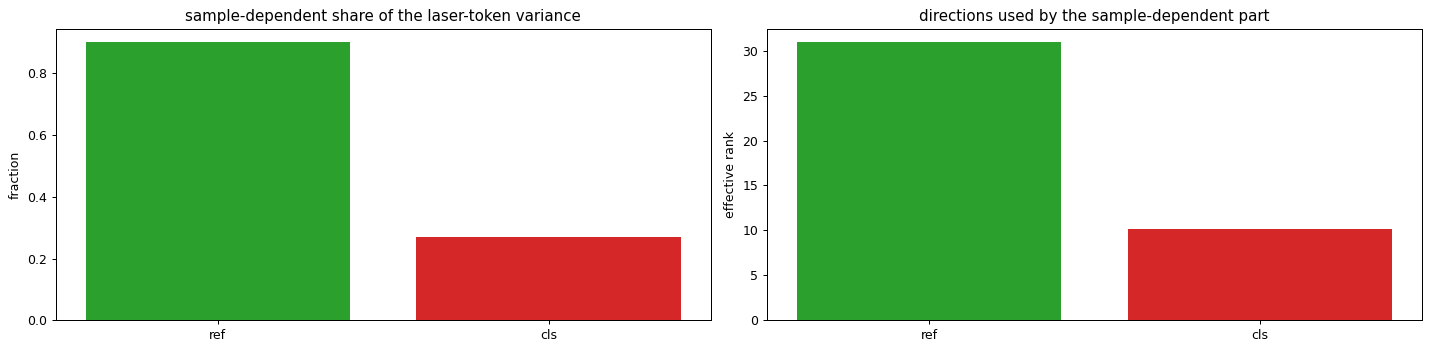

{'ref': (0.9, 30.9), 'cls': (0.27, 10.2)}


In [12]:
def stats(T):
    T = T.double(); dev = T - T.mean(0, keepdim=True)
    frac = (dev.pow(2).sum() / (T - T.mean((0, 1), keepdim=True)).pow(2).sum()).item()
    s = torch.linalg.svdvals(dev.flatten(0, 1)) ** 2; return frac, (s.sum() ** 2 / (s ** 2).sum()).item()
st = {n: stats(O["laser_tok"]) for n, O in [("ref", R), ("cls", C)]}
fig, axs = plt.subplots(1, 2, figsize=(16, 4))
axs[0].bar(list(st), [v[0] for v in st.values()], color=["tab:green", "tab:red"]); axs[0].set(ylabel="fraction", title="sample-dependent share of the laser-token variance")
axs[1].bar(list(st), [v[1] for v in st.values()], color=["tab:green", "tab:red"]); axs[1].set(ylabel="effective rank", title="directions used by the sample-dependent part")
plt.tight_layout(); plt.show(); print({k: (round(a, 3), round(b, 1)) for k, (a, b) in st.items()})

## 7 · the laser side, same idea
The ref's 12,800 × 1024 matrix is the same trick over lasers: cut it into 100 blocks of `(1024 × 128)`, one **per laser**.
Left: the size of each laser's block on the 10×10 wall grid. `laser_cls` instead pools 100 lasers through one shared V. Its
attention (last laser block, mean over heads) is peaked on a few lasers per sample, so here attention is "selecting", not averaging.
The laser grid and the mask image are not the same coordinates (the lasers are on the box wall), so they're shown side by side, not overlaid.

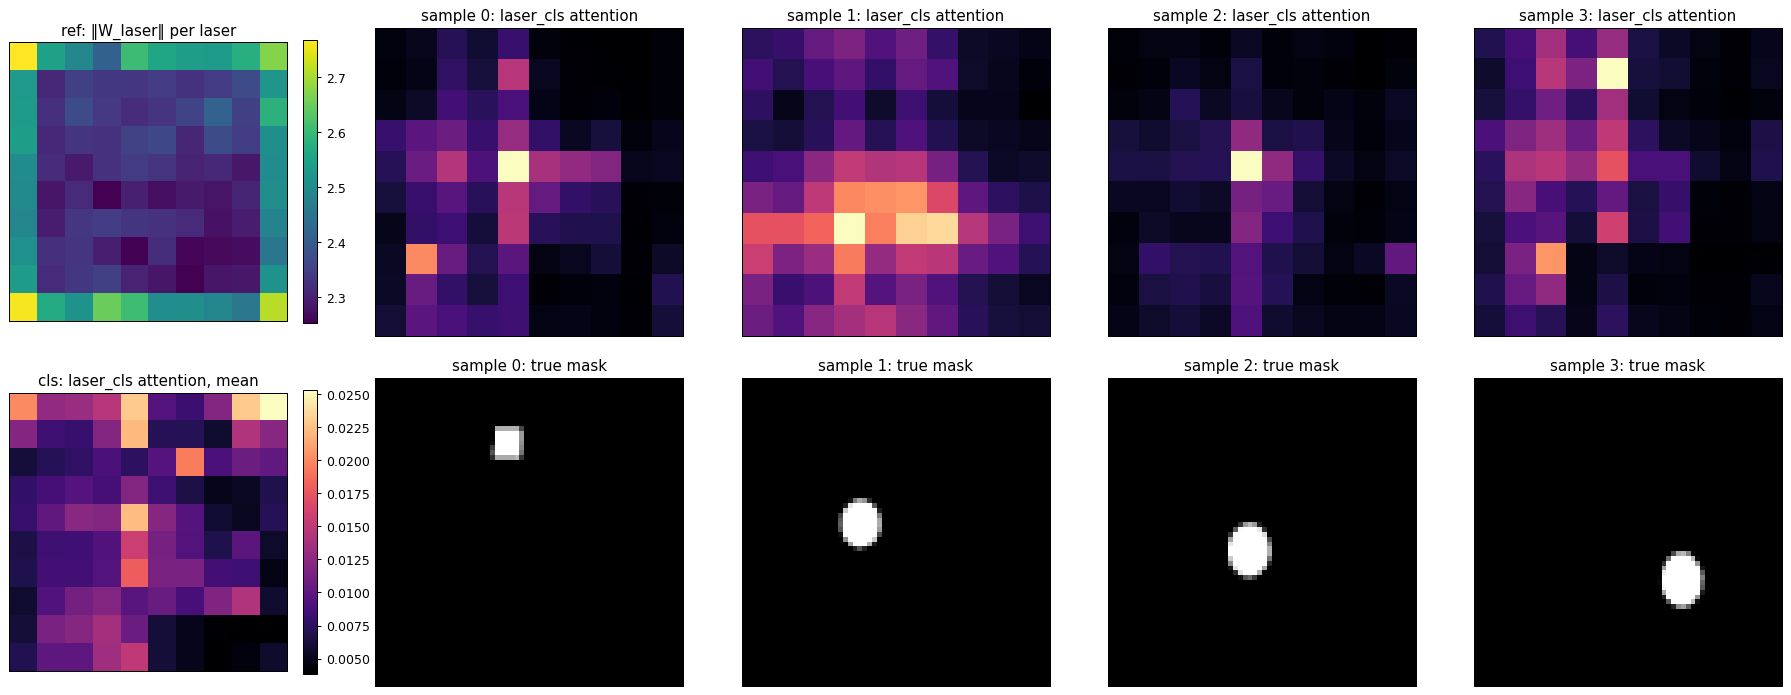

laser_cls attention: entropy 0.898 (1 = uniform), max weight 0.061 (uniform 0.01)
ref per-laser blocks: mean off-diagonal cosine 0.013 (shared = 1)


In [13]:
Wl = sd_ref["encoder.laser_enc.to_emb.2.weight"].view(1024, 100, 128)
la = C["laser_attn"][:, -1].mean(1)[:, 0, 1:]                                          # (B,100): what laser_cls reads, last block
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
im = axs[0, 0].imshow(Wl.norm(dim=(0, 2)).view(10, 10), cmap="viridis"); axs[0, 0].set_title("ref: ‖W_laser‖ per laser"); plt.colorbar(im, ax=axs[0, 0], fraction=.046)
im = axs[1, 0].imshow(la.mean(0).view(10, 10), cmap="magma"); axs[1, 0].set_title("cls: laser_cls attention, mean"); plt.colorbar(im, ax=axs[1, 0], fraction=.046)
for j, i in enumerate([0, 1, 2, 3]):
    axs[0, j + 1].imshow(la[i].view(10, 10), cmap="magma"); axs[0, j + 1].set_title(f"sample {i}: laser_cls attention")
    axs[1, j + 1].imshow(Y[i], cmap="gray"); axs[1, j + 1].set_title(f"sample {i}: true mask")
for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
le = -(la * la.clamp_min(1e-12).log()).sum(-1) / math.log(100)
print(f"laser_cls attention: entropy {le.mean():.3f} (1 = uniform), max weight {la.max(-1).values.mean():.3f} (uniform 0.01)")
c = F.normalize(Wl.permute(1, 0, 2).flatten(1), dim=1); c = c @ c.T
print(f"ref per-laser blocks: mean off-diagonal cosine {c[~torch.eye(100, dtype=bool)].mean():.3f} (shared = 1)")

## 8 · the fix: band-specific weights before the pooling (a per-band embedding `W_x^b`)
If every band has its own embedding matrix, each band's content starts out in **its own directions**, so even a plain average keeps
band identity: `mean_b(W_x^b x_b) = (1/18) · [W_x^1 … W_x^18] · concat(x_1 … x_18)`, which is exactly a flatten + Linear.
Checked on the toy (A vs B, and the 4-band pair A' vs B' that attention could not separate) and numerically on random real-sized tensors.

In [14]:
Wx = torch.randn(3, 2, 2, generator=g).round(decimals=1)                              # per-band embeddings, 3-band toy
Wx4 = torch.randn(4, 2, 2, generator=g).round(decimals=1)                             # and for the 4-band toy
perband_embed = lambda W, x: torch.einsum("bij,bj->bi", W, x).mean(0)                  # untied embed, then a plain average
print("per-band embed + average:  A ", [round(v, 3) for v in perband_embed(Wx, xA).tolist()], " B ", [round(v, 3) for v in perband_embed(Wx, xB).tolist()])
print("                           A'", [round(v, 3) for v in perband_embed(Wx4, xA4).tolist()], " B'", [round(v, 3) for v in perband_embed(Wx4, xB4).tolist()])
Wx_real, x = torch.randn(18, 128, 130), torch.randn(4, 18, 130)
lhs = torch.einsum("bdi,nbi->nbd", Wx_real, x).mean(1)                                 # per-band embed, mean over bands
rhs = x.flatten(1) @ Wx_real.permute(1, 0, 2).reshape(128, -1).T / 18                  # flatten + one Linear(2340 -> 128)
print("max |mean_b W_x^b x_b - flatten·Linear / 18| =", (lhs - rhs).abs().max().item())

per-band embed + average:  A  [-0.3, 0.033]  B  [-0.267, 0.1]
                           A' [-1.075, 0.825]  B' [-0.725, 0.05]
max |mean_b W_x^b x_b - flatten·Linear / 18| = 2.4437904357910156e-06


## summary
- **ref**: the flatten + Linear is 18 different matrices `W_b`, one per band (cosine between them ≈ 0). The gate in front of it is nearly
  uniform, so it isn't what does the work; the per-band matrices are.
- **cls**: the `freq_cls` attention over the 18 bands is nearly uniform, and every band goes through the same `V`. So the laser token is
  roughly `V · (average band)`: the bands are folded on top of each other. A linear probe can read each band's energy far worse from it,
  less of the token depends on the sample, and it uses fewer directions.
- the laser side has the same structure (per-laser blocks vs one shared V), but `laser_cls` attention is peaked, so it can select lasers
  rather than average them. Location is still the thing to watch there.
- **fix**: band-specific weights before the pooling, i.e. a per-band embedding `W_x^b`. With no blocks, per-band embedding + average is exactly
  flatten + Linear.

Predictions for the 200-ep queue (`scripts/transformer2_cls_split.sh`): `freqcls` alone costs the most; `freqcls8` (8 freq blocks) recovers
part of it (more depth = more chances to mix position into content); `lasercls` alone costs less, but shows up in `com_err` / unseen position.